We now seek to draw samples from a discrete distribution. To do so i will sample from a poisson candidate and use the MH algorithm so sample the target. To check for convergence of the correct distribution i will compare the emperical CDF with the actual CDF

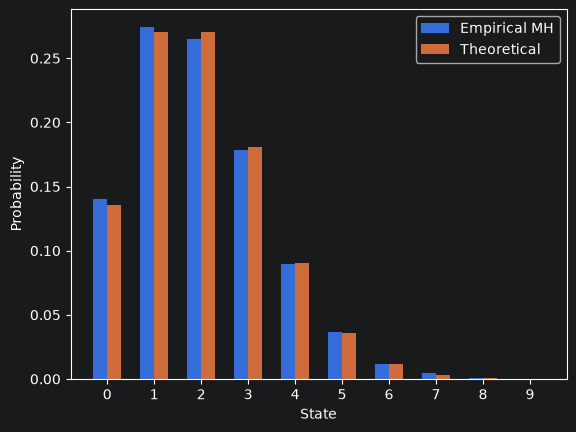

In [39]:
import math
import numpy as np
from scipy.stats import poisson
# Target up to normalization
lam = 2
m_max = 10

# Target
from scipy.special import factorial

pi = lambda i: np.where(
    (i >= 0) & (i < m_max),
    lam**i / factorial(i),
    0
)

# Proposal sampler
sampler = lambda x: poisson.rvs(mu= x + 0.5*(lam - x))

# Proposal probability
density = lambda x, given: poisson.pmf(
    int(x), mu= given + 0.5*(lam - given))

from week11 import *

S = metropolis_hastings_sampler(proposal_sampler=sampler,
                                proposal_density=density,
                                target_density=pi,
                                x0= 1,
                                n_samples= 10000)

import matplotlib.pyplot as plt

# Normalising constant
z = np.sum([lam**i / factorial(i) for i in range(m_max)])

# States and theoretical probabilities
ii = np.arange(m_max)
theoretical = pi(ii) / z

# Empirical probabilities
empirical = np.array([np.mean(S[0] == i) for i in ii])

# Plot
plt.bar(ii - 0.15, empirical, width=0.3, label="Empirical MH")
plt.bar(ii + 0.15, theoretical, width=0.3, label="Theoretical")
plt.xlabel("State")
plt.ylabel("Probability")
plt.xticks(ii)
plt.legend()
plt.show()
